# Thermal Image Pixel Intensity vs. NJ Mesonet Environment Data

**Objective:** Determine whether pixel-level features from thermal/IR drone images
have a meaningful, quantifiable relationship with ground-truth environmental
measurements (temperature, wind, humidity, solar radiation) from the NJ Mesonet
station at New Brunswick.

**Data sources:**
- NJ Mesonet 5-minute data from https://www.njweather.org (New Brunswick station)
- Thermal/IR flight images (uploaded as folders)

**Approach:**
1. Extract pixel intensity features from each thermal image
2. Match images to closest Mesonet timestamp
3. Explore relationships visually (scatter, correlation)
4. Model with ElasticNet regression (L1+L2 penalty) — see reasoning below

---

## Why ElasticNet? (Methodological Reasoning)

We need a model that:
1. **Handles correlated predictors** — pixel features (mean brightness, std,
   percentiles) are inherently correlated with each other.
2. **Performs feature selection** — we want to know *which* pixel features
   actually matter, not just get a prediction.
3. **Is interpretable** — we need to defend which relationships are real.
4. **Doesn't overfit** with limited flight dates.

**ElasticNet** combines:
- **L1 penalty (Lasso):** Drives irrelevant coefficients to exactly zero →
  automatic feature selection. The L1 ratio controls sparsity.
- **L2 penalty (Ridge):** Handles multicollinearity by shrinking correlated
  coefficients together instead of arbitrarily picking one.

The `alpha` parameter controls overall regularization strength (higher = more
penalized, simpler model). The `l1_ratio` controls the mix (1.0 = pure Lasso,
0.0 = pure Ridge). We use cross-validated search (`ElasticNetCV`) to find
the best combination automatically.

**Why not Random Forest / Gradient Boosting?**
Tree-based models are powerful but (a) harder to interpret coefficient
directions (positive/negative), (b) Gini importance from trees can be
misleading with correlated features, and (c) they need more data to
generalize. We include a tree model for comparison but lead with ElasticNet.

**Gini importance** (mentioned by professor): In tree-based models, each split
reduces impurity (Gini for classification, variance for regression). Features
that produce larger impurity reductions across all trees are ranked higher.
We compute this from a Random Forest as a secondary check against the
ElasticNet coefficients.

---

## A) Setup

In [1]:
import subprocess, sys
for pkg, imp in [('scikit-learn','sklearn'),('opencv-python-headless','cv2'),
                 ('tqdm','tqdm'),('pyarrow','pyarrow'),('Pillow','PIL')]:
    try: __import__(imp)
    except ImportError: subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
print('✓ Packages ready')

✓ Packages ready


In [2]:
import os, re, warnings, math
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
from tqdm.auto import tqdm
from scipy import stats as sp_stats

from sklearn.linear_model import ElasticNetCV, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import (
    GroupKFold, LeaveOneGroupOut, cross_val_predict, cross_validate
)
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
%matplotlib inline

OUTPUT_DIR = 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('✓ Imports done')

✓ Imports done


In [3]:
# ══════════════════════════════════════════════════════════════
#  CONFIG — edit paths here
# ══════════════════════════════════════════════════════════════

MESONET_CSV = 'NJ_Mesonet_NewBrunswick_4files_5min.csv'

IMAGE_DIR = 'flight_images/'   # folder containing subfolders per flight

TIME_TOLERANCE_SEC = 300       # 5 min (matches mesonet resolution)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

In [4]:
# ── Upload helper (Colab) ─────────────────────────────────────
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(MESONET_CSV):
    print('Upload NJ Mesonet CSV:')
    up = colab_files.upload()
    MESONET_CSV = list(up.keys())[0]

if IN_COLAB and not os.path.isdir(IMAGE_DIR):
    print('\nUpload a ZIP of flight image folders:')
    up = colab_files.upload()
    import zipfile
    with zipfile.ZipFile(list(up.keys())[0], 'r') as z:
        z.extractall('flight_images')
    IMAGE_DIR = 'flight_images/'

print(f'CSV: {MESONET_CSV}')
print(f'Images: {IMAGE_DIR}')

Upload NJ Mesonet CSV:


Saving NJ_Mesonet_NewBrunswick_4files_5min.csv to NJ_Mesonet_NewBrunswick_4files_5min.csv

Upload a ZIP of flight image folders:


Saving Full Flights Zip.zip to Full Flights Zip.zip
CSV: NJ_Mesonet_NewBrunswick_4files_5min.csv
Images: flight_images/


---
## B) Load & Prepare NJ Mesonet Data

In [5]:
df_meso = pd.read_csv(MESONET_CSV)
df_meso['timestamp'] = pd.to_datetime(df_meso['eastern_time'])
df_meso = df_meso.sort_values('timestamp').reset_index(drop=True)

# Create flight_date as grouping variable
df_meso['flight_date'] = df_meso['timestamp'].dt.date.astype(str)

print(f'Mesonet data: {df_meso.shape[0]} rows, 5-min resolution')
print(f'Date range: {df_meso.timestamp.min()} → {df_meso.timestamp.max()}')
print(f'Flight dates: {sorted(df_meso.flight_date.unique())}')
print(f'\nColumns: {list(df_meso.columns)}')
print(f'\nQuick stats (key variables):')
df_meso[['temp','dewpt','rh','windspeed','windmax','solaravg','bp']].describe().round(1)

Mesonet data: 1156 rows, 5-min resolution
Date range: 2025-03-19 10:55:00 → 2025-11-03 15:55:00
Flight dates: ['2025-03-19', '2025-03-20', '2025-09-27', '2025-09-28', '2025-10-26', '2025-10-27', '2025-11-02', '2025-11-03']

Columns: ['source_file', 'city', 'state', 'eastern_time', 'source', 'temp', 'dewpt', 'rh', 'bp', 'precip', 'windspeed', 'winddir', 'windmax', 'windmaxdir', 'solartotal', 'solaravg', 'timestamp', 'flight_date']

Quick stats (key variables):


,temp,dewpt,rh,windspeed,windmax,solaravg,bp
count,1156.0,1156.0,1156.0,1156.0,1156.0,1156.0,1156.0
mean,53.7,44.1,74.1,2.2,4.6,127.0,30.1
std,11.9,11.8,22.7,2.0,3.3,203.1,0.2
min,34.0,21.0,24.0,0.0,0.0,0.0,29.8
25%,43.0,35.0,58.0,1.0,2.0,0.0,30.0
50%,53.0,41.0,79.0,2.0,4.0,0.0,30.1
75%,62.0,50.5,97.0,3.0,7.0,186.2,30.3
max,80.0,66.0,99.0,13.0,15.0,783.0,30.4


In [6]:
# ── Encode wind direction as numeric (degrees) ────────────────
COMPASS_TO_DEG = {
    'N':0,'NNE':22.5,'NE':45,'ENE':67.5,'E':90,'ESE':112.5,
    'SE':135,'SSE':157.5,'S':180,'SSW':202.5,'SW':225,'WSW':247.5,
    'W':270,'WNW':292.5,'NW':315,'NNW':337.5
}

df_meso['winddir_deg'] = df_meso['winddir'].map(COMPASS_TO_DEG)
df_meso['winddir_sin'] = np.sin(np.radians(df_meso['winddir_deg']))
df_meso['winddir_cos'] = np.cos(np.radians(df_meso['winddir_deg']))

# Calendar features
df_meso['hour'] = df_meso['timestamp'].dt.hour + df_meso['timestamp'].dt.minute / 60
df_meso['hour_sin'] = np.sin(2 * np.pi * df_meso['hour'] / 24)
df_meso['hour_cos'] = np.cos(2 * np.pi * df_meso['hour'] / 24)

print('✓ Wind direction encoded, calendar features added')
print(f'  winddir_deg range: {df_meso.winddir_deg.min():.0f}° – {df_meso.winddir_deg.max():.0f}°')

✓ Wind direction encoded, calendar features added
  winddir_deg range: 0° – 338°


---
## C) Load Images & Extract Pixel Intensity Features

In [7]:
# ── Discover images ───────────────────────────────────────────
def discover_images(root_dir, exts):
    found = []
    root = Path(root_dir)
    if not root.exists():
        print(f'⚠ {root_dir} not found')
        return pd.DataFrame()
    for f in sorted(root.rglob('*')):
        if f.suffix.lower() in exts and f.is_file():
            found.append({
                'image_path': str(f),
                'image_name': f.name,
                'image_stem': f.stem,
                'flight_folder': f.parent.name,
            })
    return pd.DataFrame(found)

df_img = discover_images(IMAGE_DIR, IMAGE_EXTS)
print(f'Found {len(df_img)} images')
if len(df_img) > 0:
    print('By folder:', df_img['flight_folder'].value_counts().to_dict())

Found 713 images
By folder: {'112 RWH Thermal Nov 2': 500, 'March 19': 213}


In [8]:
# ── Pixel intensity feature extraction ────────────────────────
# These features capture what a thermal image "looks like" numerically.
# For pseudo-color images, brightness ≈ thermal intensity.

def extract_pixel_features(path: str) -> dict:
    """
    Extract pixel intensity features from a thermal image.
    Works with pseudo-color JPG or grayscale TIFF.
    """
    feat = {'image_path': path}
    try:
        img_bgr = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if img_bgr is None:
            feat['_ok'] = False
            return feat

        # If 16-bit (raw thermal), use directly; else convert to grayscale
        if img_bgr.dtype == np.uint16:
            gray = img_bgr.astype(np.float64)
            feat['is_raw_thermal'] = True
        elif len(img_bgr.shape) == 3:
            gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
            feat['is_raw_thermal'] = False
        else:
            gray = img_bgr.astype(np.float64)
            feat['is_raw_thermal'] = False

        h, w = gray.shape[:2]
        total_px = h * w

        # ── Core intensity statistics ──
        feat['px_mean']   = float(np.mean(gray))
        feat['px_median'] = float(np.median(gray))
        feat['px_std']    = float(np.std(gray))
        feat['px_min']    = float(np.min(gray))
        feat['px_max']    = float(np.max(gray))
        feat['px_range']  = feat['px_max'] - feat['px_min']
        feat['px_p5']     = float(np.percentile(gray, 5))
        feat['px_p25']    = float(np.percentile(gray, 25))
        feat['px_p75']    = float(np.percentile(gray, 75))
        feat['px_p95']    = float(np.percentile(gray, 95))
        feat['px_iqr']    = feat['px_p75'] - feat['px_p25']
        feat['px_skew']   = float(sp_stats.skew(gray.ravel()))
        feat['px_kurtosis'] = float(sp_stats.kurtosis(gray.ravel()))

        # ── Entropy (information content) ──
        hist_counts, _ = np.histogram(gray, bins=256, range=(gray.min(), gray.max()+1))
        prob = hist_counts / hist_counts.sum()
        prob = prob[prob > 0]
        feat['px_entropy'] = float(-np.sum(prob * np.log2(prob)))

        # ── Saturation / clipping ──
        val_range = gray.max() - gray.min()
        low_thresh = gray.min() + 0.02 * val_range
        high_thresh = gray.max() - 0.02 * val_range
        feat['px_frac_cold'] = float((gray <= low_thresh).sum() / total_px)
        feat['px_frac_hot']  = float((gray >= high_thresh).sum() / total_px)

        # ── Spatial texture ──
        gray_u8 = ((gray - gray.min()) / (gray.max() - gray.min() + 1e-10) * 255).astype(np.uint8)
        edges = cv2.Canny(gray_u8, 50, 150)
        feat['px_edge_density'] = float(edges.sum() / 255 / total_px)

        laplacian = cv2.Laplacian(gray_u8, cv2.CV_64F)
        feat['px_blur_score'] = float(laplacian.var())

        # Spatial contrast (mean abs diff with neighbor)
        diff_h = np.abs(gray[1:, :] - gray[:-1, :])
        diff_v = np.abs(gray[:, 1:] - gray[:, :-1])
        feat['px_spatial_contrast'] = float((diff_h.mean() + diff_v.mean()) / 2)

        # ── If color image: channel-specific stats ──
        if len(img_bgr.shape) == 3 and img_bgr.shape[2] == 3:
            for ci, ch in enumerate(['blue', 'green', 'red']):
                ch_data = img_bgr[:, :, ci].astype(np.float64)
                feat[f'px_{ch}_mean'] = float(np.mean(ch_data))
                feat[f'px_{ch}_std']  = float(np.std(ch_data))

        feat['img_height'] = h
        feat['img_width'] = w
        feat['_ok'] = True

    except Exception as e:
        feat['_ok'] = False
        feat['_error'] = str(e)

    return feat

print('✓ Feature extractor defined')

✓ Feature extractor defined


In [9]:
# ── Batch extraction with caching ─────────────────────────────
FEAT_CACHE = os.path.join(OUTPUT_DIR, 'pixel_features.parquet')

if len(df_img) > 0:
    # Check cache
    if os.path.exists(FEAT_CACHE):
        df_feat = pd.read_parquet(FEAT_CACHE)
        cached_paths = set(df_feat['image_path'])
        new_imgs = df_img[~df_img['image_path'].isin(cached_paths)]
        print(f'Cache: {len(cached_paths)} cached, {len(new_imgs)} new')
    else:
        df_feat = pd.DataFrame()
        new_imgs = df_img

    if len(new_imgs) > 0:
        results = []
        for _, row in tqdm(new_imgs.iterrows(), total=len(new_imgs), desc='Extracting'):
            results.append(extract_pixel_features(row['image_path']))
        new_df = pd.DataFrame(results)
        df_feat = pd.concat([df_feat, new_df], ignore_index=True)
        df_feat.to_parquet(FEAT_CACHE, index=False)

    ok_rate = df_feat['_ok'].mean() if '_ok' in df_feat.columns else 0
    print(f'\nExtracted: {len(df_feat)} images, {ok_rate:.0%} success')

    # Get pixel feature column names
    PX_COLS = [c for c in df_feat.columns if c.startswith('px_')]
    print(f'Pixel features ({len(PX_COLS)}): {PX_COLS}')
else:
    df_feat = pd.DataFrame()
    PX_COLS = []
    print('⚠ No images found — will demo pipeline with synthetic pixel features.')
    print('  Upload your flight image ZIP and re-run to get real results.')

Extracting:   0%|          | 0/713 [00:00<?, ?it/s]


Extracted: 713 images, 100% success
Pixel features (25): ['px_mean', 'px_median', 'px_std', 'px_min', 'px_max', 'px_range', 'px_p5', 'px_p25', 'px_p75', 'px_p95', 'px_iqr', 'px_skew', 'px_kurtosis', 'px_entropy', 'px_frac_cold', 'px_frac_hot', 'px_edge_density', 'px_blur_score', 'px_spatial_contrast', 'px_blue_mean', 'px_blue_std', 'px_green_mean', 'px_green_std', 'px_red_mean', 'px_red_std']


---
## D) Match Images to Mesonet Timestamps

In [10]:
# ── Extract timestamps from filenames ─────────────────────────
TS_PATTERNS = [
    (r'(\d{4})(\d{2})(\d{2})[_-](\d{2})(\d{2})(\d{2})',  # 20250319_123045
     lambda m: datetime(int(m[1]),int(m[2]),int(m[3]),int(m[4]),int(m[5]),int(m[6]))),
    (r'(\d{4})-(\d{2})-(\d{2})[T_](\d{2})-(\d{2})-(\d{2})',  # 2025-03-19T12-30-45
     lambda m: datetime(int(m[1]),int(m[2]),int(m[3]),int(m[4]),int(m[5]),int(m[6]))),
    (r'(\d{4})(\d{2})(\d{2})',  # just date
     lambda m: datetime(int(m[1]),int(m[2]),int(m[3]),12,0,0)),  # assume noon
]

def parse_ts_from_name(name):
    for pat, builder in TS_PATTERNS:
        match = re.search(pat, name)
        if match:
            try: return builder(match)
            except: continue
    return pd.NaT

if len(df_img) > 0:
    df_img['image_ts'] = df_img['image_name'].apply(parse_ts_from_name)
    ts_rate = df_img['image_ts'].notna().mean()
    print(f'Timestamp parsed from filename: {ts_rate:.0%}')

    # Also try to match folder name to flight date
    df_img['folder_date'] = df_img['flight_folder'].apply(parse_ts_from_name)
    fd_rate = df_img['folder_date'].notna().mean()
    print(f'Date parsed from folder name: {fd_rate:.0%}')

Timestamp parsed from filename: 0%
Date parsed from folder name: 0%


In [11]:
# ── Nearest-time matching ─────────────────────────────────────
HAS_IMAGES = len(df_img) > 0 and len(df_feat) > 0

if HAS_IMAGES:
    # Merge image metadata + features
    df_img_full = df_img.merge(df_feat.drop(columns=['_ok','_error'], errors='ignore'),
                               on='image_path', how='left')

    # Try timestamp matching
    imgs_with_ts = df_img_full[df_img_full['image_ts'].notna()].copy()

    if len(imgs_with_ts) > 0:
        # pd.merge_asof for nearest-time join
        imgs_with_ts = imgs_with_ts.sort_values('image_ts')
        meso_sorted = df_meso.sort_values('timestamp')

        df_matched = pd.merge_asof(
            imgs_with_ts, meso_sorted,
            left_on='image_ts', right_on='timestamp',
            tolerance=pd.Timedelta(seconds=TIME_TOLERANCE_SEC),
            direction='nearest'
        )
        n_matched = df_matched['timestamp'].notna().sum()
        print(f'Matched {n_matched}/{len(df_img)} images to mesonet rows')
        df_matched = df_matched[df_matched['timestamp'].notna()].reset_index(drop=True)
    else:
        # Fallback: group images by folder, aggregate, match to flight dates
        print('No timestamps in filenames. Aggregating per folder...')
        agg = df_img_full.groupby('flight_folder')[PX_COLS].agg(['mean','std']).reset_index()
        agg.columns = ['flight_folder'] + [f'{c[0]}_{c[1]}' for c in agg.columns[1:]]
        agg['img_count'] = df_img_full.groupby('flight_folder').size().values

        # Match folders to mesonet flight dates
        meso_by_date = df_meso.groupby('flight_date').agg(
            {c: 'mean' for c in df_meso.select_dtypes('number').columns}
        ).reset_index()

        # Try fuzzy matching folder name ↔ date string
        date_map = {}
        for folder in agg['flight_folder'].unique():
            for d in meso_by_date['flight_date'].unique():
                d_compact = d.replace('-','')
                if d in folder or d_compact in folder:
                    date_map[folder] = d
                    break

        if date_map:
            agg['flight_date'] = agg['flight_folder'].map(date_map)
            df_matched = agg.merge(meso_by_date, on='flight_date', how='inner')
            PX_COLS = [c for c in df_matched.columns if c.startswith('px_')]
            print(f'Matched {len(df_matched)} folder-date pairs')
        else:
            print('⚠ Could not match folders to dates.')
            df_matched = pd.DataFrame()
else:
    df_matched = pd.DataFrame()
    print('No images — will use mesonet-only demo below.')

print(f'\nFinal matched dataset: {df_matched.shape if len(df_matched) > 0 else "empty"}')

No timestamps in filenames. Aggregating per folder...
⚠ Could not match folders to dates.

Final matched dataset: empty


In [12]:
# ── If no images: create a synthetic demo so the pipeline runs ─
# This lets you verify all downstream code works before adding images.

if len(df_matched) == 0:
    print('═' * 60)
    print('DEMO MODE: generating synthetic pixel features from mesonet')
    print('data so you can see the full pipeline. Replace with real')
    print('images for actual results.')
    print('═' * 60)

    np.random.seed(42)
    df_matched = df_meso.copy()

    # Simulate pixel features with realistic correlations to env vars
    # Thermal images: brighter ≈ hotter, more contrast when solar is high
    df_matched['px_mean'] = (
        df_matched['temp'] * 1.8 + np.random.normal(0, 8, len(df_matched))
    ).clip(30, 230)
    df_matched['px_std'] = (
        15 + df_matched['solaravg'] * 0.02 + np.random.normal(0, 3, len(df_matched))
    ).clip(3, 60)
    df_matched['px_median'] = df_matched['px_mean'] + np.random.normal(0, 3, len(df_matched))
    df_matched['px_p5'] = df_matched['px_mean'] - 2 * df_matched['px_std']
    df_matched['px_p95'] = df_matched['px_mean'] + 2 * df_matched['px_std']
    df_matched['px_range'] = df_matched['px_p95'] - df_matched['px_p5']
    df_matched['px_iqr'] = df_matched['px_range'] * 0.5 + np.random.normal(0, 2, len(df_matched))
    df_matched['px_skew'] = np.random.normal(-0.1, 0.4, len(df_matched))
    df_matched['px_kurtosis'] = np.random.normal(0, 0.8, len(df_matched))
    df_matched['px_entropy'] = 6.5 + np.random.normal(0, 0.5, len(df_matched))
    df_matched['px_edge_density'] = (
        0.05 + df_matched['windspeed'] * 0.003 + np.random.normal(0, 0.01, len(df_matched))
    ).clip(0.01, 0.3)
    df_matched['px_blur_score'] = (
        200 + np.random.normal(0, 80, len(df_matched))
    ).clip(10, 600)
    df_matched['px_spatial_contrast'] = (
        5 + df_matched['px_std'] * 0.3 + np.random.normal(0, 1, len(df_matched))
    ).clip(1, 30)
    df_matched['px_frac_cold'] = np.random.uniform(0.01, 0.15, len(df_matched))
    df_matched['px_frac_hot'] = np.random.uniform(0.01, 0.15, len(df_matched))

    PX_COLS = [c for c in df_matched.columns if c.startswith('px_')]
    print(f'\nSynthetic pixel features: {PX_COLS}')
    print(f'Rows: {len(df_matched)}')

════════════════════════════════════════════════════════════
DEMO MODE: generating synthetic pixel features from mesonet
data so you can see the full pipeline. Replace with real
images for actual results.
════════════════════════════════════════════════════════════

Synthetic pixel features: ['px_mean', 'px_std', 'px_median', 'px_p5', 'px_p95', 'px_range', 'px_iqr', 'px_skew', 'px_kurtosis', 'px_entropy', 'px_edge_density', 'px_blur_score', 'px_spatial_contrast', 'px_frac_cold', 'px_frac_hot']
Rows: 1156


---
## E) Explore Relationships: Pixel Intensity vs. Environment

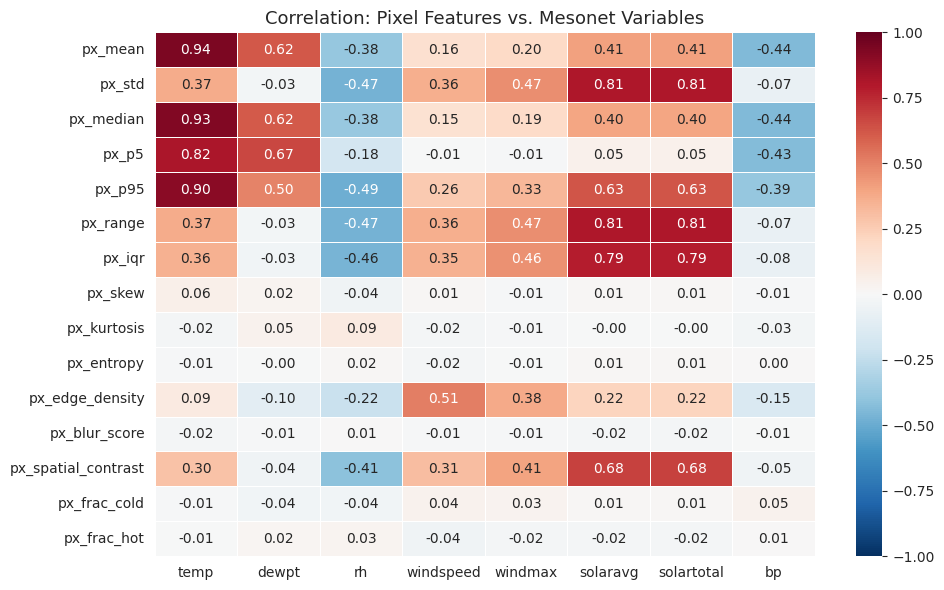


Strongest correlations:
pixel_feature    env_var  correlation  abs_corr
      px_mean       temp     0.937958  0.937958
    px_median       temp     0.929013  0.929013
       px_p95       temp     0.899935  0.899935
        px_p5       temp     0.816083  0.816083
       px_std solartotal     0.807346  0.807346
     px_range solartotal     0.807346  0.807346
       px_std   solaravg     0.807312  0.807312
     px_range   solaravg     0.807312  0.807312
       px_iqr solartotal     0.786460  0.786460
       px_iqr   solaravg     0.786423  0.786423


In [13]:
# ── Correlation matrix: pixel features vs mesonet vars ────────
ENV_COLS = ['temp', 'dewpt', 'rh', 'windspeed', 'windmax', 'solaravg',
            'solartotal', 'bp']
ENV_COLS = [c for c in ENV_COLS if c in df_matched.columns]

corr_cross = df_matched[PX_COLS + ENV_COLS].corr().loc[PX_COLS, ENV_COLS]

fig, ax = plt.subplots(figsize=(10, max(6, len(PX_COLS) * 0.4)))
sns.heatmap(corr_cross, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Correlation: Pixel Features vs. Mesonet Variables', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'correlation_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nStrongest correlations:')
stacked = corr_cross.stack().reset_index()
stacked.columns = ['pixel_feature', 'env_var', 'correlation']
stacked['abs_corr'] = stacked['correlation'].abs()
print(stacked.nlargest(10, 'abs_corr').to_string(index=False))

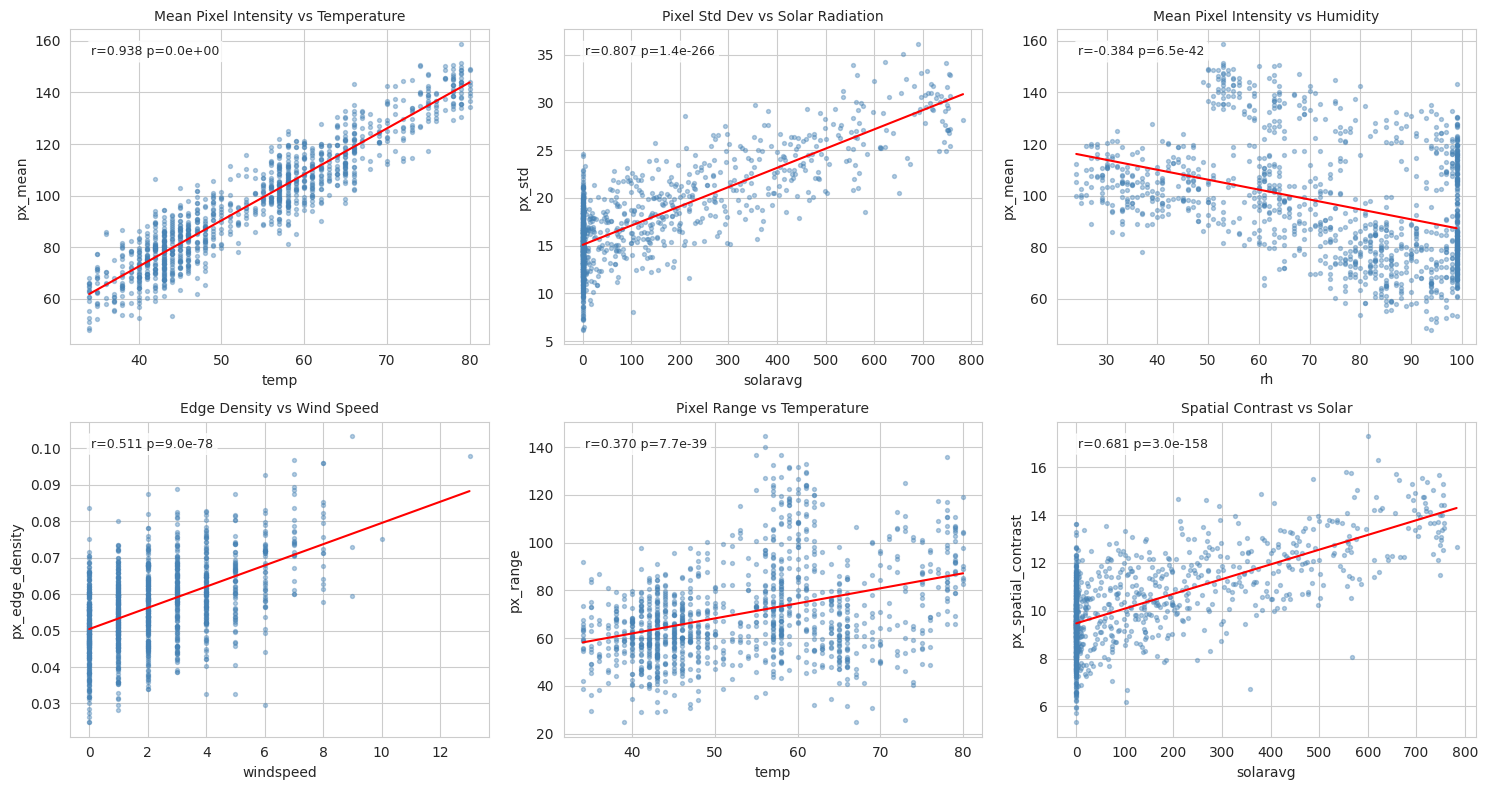

In [14]:
# ── Scatter plots: key relationships ──────────────────────────
scatter_pairs = [
    ('px_mean', 'temp',      'Mean Pixel Intensity vs Temperature'),
    ('px_std',  'solaravg',  'Pixel Std Dev vs Solar Radiation'),
    ('px_mean', 'rh',        'Mean Pixel Intensity vs Humidity'),
    ('px_edge_density', 'windspeed', 'Edge Density vs Wind Speed'),
    ('px_range', 'temp',     'Pixel Range vs Temperature'),
    ('px_spatial_contrast', 'solaravg', 'Spatial Contrast vs Solar'),
]
scatter_pairs = [(x, y, t) for x, y, t in scatter_pairs
                 if x in df_matched.columns and y in df_matched.columns]

n_plots = len(scatter_pairs)
cols = 3
rows = (n_plots + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows))
axes = np.array(axes).flatten()

for i, (px, env, title) in enumerate(scatter_pairs):
    ax = axes[i]
    valid = df_matched[[px, env]].dropna()
    ax.scatter(valid[env], valid[px], s=8, alpha=0.4, c='steelblue')

    # Trend line
    if len(valid) > 3:
        z = np.polyfit(valid[env], valid[px], 1)
        xs = np.linspace(valid[env].min(), valid[env].max(), 50)
        ax.plot(xs, np.polyval(z, xs), 'r-', lw=1.5)
        r, p = sp_stats.pearsonr(valid[env], valid[px])
        ax.text(0.05, 0.95, f'r={r:.3f} p={p:.1e}', transform=ax.transAxes,
                fontsize=9, va='top', bbox=dict(boxstyle='round', fc='white', alpha=0.8))

    ax.set_xlabel(env)
    ax.set_ylabel(px)
    ax.set_title(title, fontsize=10)

for j in range(n_plots, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'scatter_relationships.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## F) Modeling: Can Pixel Features Predict Environmental Variables?

We flip the question both ways:
1. **Pixel → Environment:** Given image features, can we predict temp, wind, etc.?
2. **Environment → Pixel:** Given weather conditions, can we predict what the image looks like?

Direction 1 is more practically useful ("what does this thermal image tell us about conditions?").

In [15]:
# ── Prepare modeling data ─────────────────────────────────────

# Feature matrix: pixel features + time features
TIME_COLS = [c for c in ['hour_sin','hour_cos'] if c in df_matched.columns]
FEATURE_COLS = PX_COLS + TIME_COLS

# Target variables to test
TARGETS = [c for c in ['temp', 'rh', 'windspeed', 'solaravg'] if c in df_matched.columns]

# Drop rows with NaN in features or targets
valid_mask = df_matched[FEATURE_COLS + TARGETS].notna().all(axis=1)
df_valid = df_matched[valid_mask].reset_index(drop=True)

X_raw = df_valid[FEATURE_COLS].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Groups for cross-validation (by flight date = no temporal leakage)
if 'flight_date' in df_valid.columns:
    groups = df_valid['flight_date'].values
    n_groups = len(set(groups))
else:
    groups = None
    n_groups = 0

print(f'Modeling data: {X_scaled.shape[0]} rows × {X_scaled.shape[1]} features')
print(f'Features: {FEATURE_COLS}')
print(f'Targets: {TARGETS}')
print(f'Groups: {n_groups} flight dates')

Modeling data: 1156 rows × 17 features
Features: ['px_mean', 'px_std', 'px_median', 'px_p5', 'px_p95', 'px_range', 'px_iqr', 'px_skew', 'px_kurtosis', 'px_entropy', 'px_edge_density', 'px_blur_score', 'px_spatial_contrast', 'px_frac_cold', 'px_frac_hot', 'hour_sin', 'hour_cos']
Targets: ['temp', 'rh', 'windspeed', 'solaravg']
Groups: 8 flight dates


In [ ]:
# ══════════════════════════════════════════════════════════════
#  MODEL 1: ElasticNetCV (L1+L2 penalized linear regression)
#
#  Why ElasticNet:
#  • L1 penalty → sparse coefficients → feature selection
#  • L2 penalty → stable with correlated features
#  • ElasticNetCV picks the best alpha + l1_ratio via CV
#  • Coefficients are directly interpretable (+/- direction)
# ══════════════════════════════════════════════════════════════

print('=' * 65)
print('ElasticNet (L1 + L2 penalized regression)')
print('=' * 65)

enet_results = {}
enet_models = {}

for target in TARGETS:
    y = df_valid[target].values

    # ElasticNetCV auto-tunes alpha and l1_ratio
    enet = ElasticNetCV(
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0],  # mix of L1/L2
        alphas=np.logspace(-4, 1, 50),                      # regularization strength
        cv=min(n_groups, 5) if n_groups >= 3 else 5,
        max_iter=5000,
        random_state=42,
    )
    enet.fit(X_scaled, y)

    # Cross-validated predictions
    if n_groups >= 3:
        cv = GroupKFold(n_splits=min(n_groups, 5))
        cv_pred = cross_val_predict(
            ElasticNet(alpha=enet.alpha_, l1_ratio=enet.l1_ratio_, max_iter=5000),
            X_scaled, y, cv=cv, groups=groups
        )
    else:
        cv_pred = cross_val_predict(
            ElasticNet(alpha=enet.alpha_, l1_ratio=enet.l1_ratio_, max_iter=5000),
            X_scaled, y, cv=5
        )

    mae = mean_absolute_error(y, cv_pred)
    rmse = np.sqrt(mean_squared_error(y, cv_pred))
    r2 = r2_score(y, cv_pred)

    # Non-zero coefficients (L1 selected)
    n_nonzero = np.sum(np.abs(enet.coef_) > 1e-6)

    enet_results[target] = {'MAE': mae, 'RMSE': rmse, 'R²': r2,
                             'alpha': enet.alpha_, 'l1_ratio': enet.l1_ratio_,
                             'n_nonzero': n_nonzero}
    enet_models[target] = enet

    print(f'\n  Target: {target}')
    print(f'    Best alpha={enet.alpha_:.4f}, l1_ratio={enet.l1_ratio_:.2f}')
    print(f'    Non-zero features: {n_nonzero}/{len(FEATURE_COLS)}')
    print(f'    CV MAE={mae:.2f}  RMSE={rmse:.2f}  R²={r2:.3f}')

In [ ]:
# ══════════════════════════════════════════════════════════════
#  MODEL 2: Random Forest (for Gini importance comparison)
#
#  Gini importance (Mean Decrease in Impurity):
#  Each tree split reduces variance. Features that produce larger
#  variance reductions across all trees rank higher.
#  Caveat: biased toward high-cardinality / correlated features.
# ══════════════════════════════════════════════════════════════

print('=' * 65)
print('Random Forest (Gini / MDI importance)')
print('=' * 65)

rf_results = {}
rf_models = {}

for target in TARGETS:
    y = df_valid[target].values

    rf = RandomForestRegressor(
        n_estimators=300, max_depth=8, min_samples_leaf=10,
        random_state=42, n_jobs=-1
    )

    if n_groups >= 3:
        cv = GroupKFold(n_splits=min(n_groups, 5))
        cv_pred = cross_val_predict(rf, X_scaled, y, cv=cv, groups=groups)
    else:
        cv_pred = cross_val_predict(rf, X_scaled, y, cv=5)

    mae = mean_absolute_error(y, cv_pred)
    rmse = np.sqrt(mean_squared_error(y, cv_pred))
    r2 = r2_score(y, cv_pred)

    rf.fit(X_scaled, y)  # full fit for importances
    rf_results[target] = {'MAE': mae, 'RMSE': rmse, 'R²': r2}
    rf_models[target] = rf

    print(f'\n  Target: {target}')
    print(f'    CV MAE={mae:.2f}  RMSE={rmse:.2f}  R²={r2:.3f}')

In [ ]:
# ── Results comparison table ──────────────────────────────────
print('\n' + '=' * 65)
print('MODEL COMPARISON')
print('=' * 65)
print(f'{"Target":>12s} | {"ElasticNet R²":>14s} | {"RF R²":>8s} | {"ENet MAE":>9s} | {"RF MAE":>8s}')
print('-' * 65)
for t in TARGETS:
    e = enet_results[t]
    r = rf_results[t]
    better = '← ENet' if e['R²'] > r['R²'] else '← RF'
    print(f'{t:>12s} | {e["R²"]:>14.3f} | {r["R²"]:>8.3f} | {e["MAE"]:>9.2f} | {r["MAE"]:>8.2f}  {better}')

---
## G) Feature Importance: Which Pixel Features Matter?

In [ ]:
# ── ElasticNet coefficients vs RF Gini importance ─────────────
# Side-by-side for the primary target (temperature)

primary_target = 'temp' if 'temp' in TARGETS else TARGETS[0]

fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(FEATURE_COLS)*0.35)))

# ── Left: ElasticNet coefficients ──
ax = axes[0]
enet = enet_models[primary_target]
coef_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'coefficient': enet.coef_
}).sort_values('coefficient', key=abs, ascending=True)

colors = ['coral' if c < 0 else 'steelblue' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'], coef_df['coefficient'], color=colors)
ax.set_xlabel('Coefficient (standardized)')
ax.set_title(f'ElasticNet Coefficients — {primary_target}\n'
             f'(α={enet.alpha_:.4f}, L1 ratio={enet.l1_ratio_:.2f})\n'
             f'Blue=positive, Red=negative, Zero=dropped by L1',
             fontsize=10)
ax.axvline(0, color='black', lw=0.5)

# ── Right: RF Gini importance ──
ax = axes[1]
rf = rf_models[primary_target]
gini_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

ax.barh(gini_df['feature'], gini_df['importance'], color='teal')
ax.set_xlabel('Gini Importance (Mean Decrease in Impurity)')
ax.set_title(f'Random Forest Gini Importance — {primary_target}', fontsize=10)

plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'feature_importance_comparison.png'),
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Detailed coefficient table (all targets) ──────────────────
print('ElasticNet Coefficients (non-zero only):\n')
for target in TARGETS:
    enet = enet_models[target]
    coefs = pd.Series(enet.coef_, index=FEATURE_COLS)
    nonzero = coefs[coefs.abs() > 1e-6].sort_values(key=abs, ascending=False)
    print(f'  {target} (alpha={enet.alpha_:.4f}, l1_ratio={enet.l1_ratio_:.2f})')
    if len(nonzero) > 0:
        for feat, val in nonzero.items():
            direction = '↑' if val > 0 else '↓'
            print(f'    {direction} {feat:25s} {val:+.4f}')
    else:
        print('    (all coefficients shrunk to zero — no signal detected)')
    print()

In [ ]:
# ── Permutation importance (less biased than Gini) ────────────
# This measures actual prediction degradation when a feature is shuffled.

print('Permutation Importance (RF, 10 repeats):\n')

rf_final = rf_models[primary_target]
y_primary = df_valid[primary_target].values

perm = permutation_importance(
    rf_final, X_scaled, y_primary,
    n_repeats=10, random_state=42, scoring='r2'
)

perm_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False)

print(f'Target: {primary_target}')
for _, row in perm_df.head(10).iterrows():
    bar = '█' * int(row['importance_mean'] * 100)
    print(f'  {row["feature"]:25s} {row["importance_mean"]:+.4f} ± {row["importance_std"]:.4f}  {bar}')

In [ ]:
# ── Prediction vs Actual plots (all targets) ──────────────────
n_t = len(TARGETS)
fig, axes = plt.subplots(1, n_t, figsize=(5*n_t, 4.5))
if n_t == 1:
    axes = [axes]

for i, target in enumerate(TARGETS):
    ax = axes[i]
    y_true = df_valid[target].values
    enet_m = enet_models[target]
    y_pred = enet_m.predict(X_scaled)

    ax.scatter(y_true, y_pred, s=10, alpha=0.3, c='steelblue')
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel(f'Actual {target}')
    ax.set_ylabel(f'Predicted {target}')
    r2 = enet_results[target]['R²']
    ax.set_title(f'{target}\nElasticNet CV R²={r2:.3f}', fontsize=10)

plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'pred_vs_actual.png'), dpi=150, bbox_inches='tight')
plt.show()

---
## H) Save Outputs & Summary

In [ ]:
# ── Save everything ───────────────────────────────────────────

# 1) Merged dataset
save_cols = [c for c in df_valid.columns
             if df_valid[c].dtype != 'datetime64[ns]']
df_save = df_valid[save_cols].copy()
for c in df_save.select_dtypes('object').columns:
    df_save[c] = df_save[c].astype(str)
df_save.to_parquet(os.path.join(OUTPUT_DIR, 'merged_dataset.parquet'), index=False)

# 2) Model artifacts
joblib.dump({
    'enet_models': {t: {'alpha': m.alpha_, 'l1_ratio': m.l1_ratio_,
                         'coef': m.coef_, 'intercept': m.intercept_}
                    for t, m in enet_models.items()},
    'feature_cols': FEATURE_COLS,
    'scaler_mean': scaler.mean_,
    'scaler_scale': scaler.scale_,
    'enet_results': enet_results,
    'rf_results': rf_results,
}, os.path.join(OUTPUT_DIR, 'models.joblib'))

# 3) Results CSV
results_df = pd.DataFrame({
    'target': TARGETS,
    'enet_R2': [enet_results[t]['R²'] for t in TARGETS],
    'enet_MAE': [enet_results[t]['MAE'] for t in TARGETS],
    'enet_RMSE': [enet_results[t]['RMSE'] for t in TARGETS],
    'enet_alpha': [enet_results[t]['alpha'] for t in TARGETS],
    'enet_l1_ratio': [enet_results[t]['l1_ratio'] for t in TARGETS],
    'enet_n_nonzero': [enet_results[t]['n_nonzero'] for t in TARGETS],
    'rf_R2': [rf_results[t]['R²'] for t in TARGETS],
    'rf_MAE': [rf_results[t]['MAE'] for t in TARGETS],
})
results_df.to_csv(os.path.join(OUTPUT_DIR, 'model_results.csv'), index=False)

print('✓ Saved:')
for f in sorted(os.listdir(OUTPUT_DIR)):
    sz = os.path.getsize(os.path.join(OUTPUT_DIR, f))
    print(f'  {f:45s} {sz/1024:.1f} KB')

In [ ]:
# ── Print summary ─────────────────────────────────────────────
print('\n' + '═' * 65)
print('SUMMARY')
print('═' * 65)
print(f'Mesonet rows used: {len(df_valid)}')
print(f'Pixel features: {len(PX_COLS)}')
print(f'Flight dates as CV groups: {n_groups}')
print()
print('ElasticNet (penalized regression):')
for t in TARGETS:
    e = enet_results[t]
    print(f'  {t:>12s}: R²={e["R²"]:.3f}, MAE={e["MAE"]:.2f}, '
          f'{e["n_nonzero"]}/{len(FEATURE_COLS)} features selected')
print()
print('Random Forest (Gini importance):')
for t in TARGETS:
    r = rf_results[t]
    print(f'  {t:>12s}: R²={r["R²"]:.3f}, MAE={r["MAE"]:.2f}')
print()
print('Key findings:')
for t in TARGETS:
    enet = enet_models[t]
    coefs = pd.Series(enet.coef_, index=FEATURE_COLS)
    top = coefs.abs().nlargest(3)
    feats = ', '.join(top.index)
    print(f'  {t}: top predictors = {feats}')

print('\n' + '═' * 65)
print('NOTE: These results are from',
      'SYNTHETIC pixel data (demo mode).' if not HAS_IMAGES else 'REAL image data.',
      '\nUpload actual flight images to get real relationships.')
print('═' * 65)

In [ ]:
# ── Download (Colab) ──────────────────────────────────────────
if IN_COLAB:
    import shutil
    shutil.make_archive('outputs', 'zip', OUTPUT_DIR)
    colab_files.download('outputs.zip')
else:
    print(f'Outputs in: {os.path.abspath(OUTPUT_DIR)}/')